## B. Data preparation

### B.1. Split the Dataset

#### Load the datasets from csv files

In [1]:
import pandas as pd
data_ms = pd.read_csv('data/mushroom_dataset.csv')
X = data_ms.iloc[:, 1:-1]
Y = data_ms['Mushroom']

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, stratify=Y, test_size=0.33, random_state=42)
X_train.head()

,age,gender,education,country,ethnicity,nscore,escore,oscore,ascore,cscore,impuslive,ss
105,0.49788,-0.48246,-0.05921,0.96082,-0.31685,-2.21844,0.47617,-1.82919,-0.76096,2.04506,-1.37983,-1.54858
73,1.09449,-0.48246,-0.05921,0.96082,-0.31685,-0.67825,-0.57545,-0.31776,0.28783,1.13407,-0.71126,-0.21575
279,1.09449,-0.48246,1.16365,0.96082,-0.31685,-1.32828,0.80523,0.29338,0.43852,0.41594,0.19268,-0.52593
1404,-0.07854,0.48246,1.16365,0.96082,-0.31685,-0.79151,0.80523,1.24033,1.28610,0.41594,0.19268,1.22470
508,0.49788,0.48246,1.16365,-0.28519,-0.31685,-1.05308,1.11406,-0.31776,0.28783,0.12331,-1.37983,-0.52593


In [3]:
type(X_test)

pandas.core.frame.DataFrame

In [4]:
from collections import Counter
counter_train = Counter(Y_train)
print(" training data:", counter_train)

 training data: Counter({0: 797, 1: 465})


### B.2. Define Labeled and Unlabeled Subsets

#### Function for preparing labeled and unlabeled data

In [5]:
import numpy as np

def prepare_labeled_unlabeled_data(X_train_original, Y_train_original, fraction):
    
    np.random.seed(42)
    num_labeled = int(fraction * len(Y_train_original))
    print(f"Requested number of labeled instances: {num_labeled}")

    # Randomly select indices for labeled data
    labeled_indices = np.random.choice(
        Y_train_original.index, size=num_labeled, replace=False
    )
    unlabeled_indices = X_train.index.difference(labeled_indices)
    
    # Create a copy of Y_train_full to avoid modifying the original data
    Y_train_process = Y_train_original.copy()

    # Set labels of unlabeled data to -1
    Y_train_process.loc[unlabeled_indices] = -1

    return X_train, Y_train_process



#### Get the labeled and unlabeled data on 0.1 0.2 0.3 0.4 0.5

In [6]:
fractions = [0.1, 0.2, 0.3, 0.4, 0.5]
label_subset = {}

for fraction in fractions:
    X_train_process, Y_train_process = prepare_labeled_unlabeled_data(X_train, Y_train, fraction)
    
    # Check the number of labeled and unlabeled instances
    num_labeled_actual = (Y_train_process != -1).sum()
    num_unlabeled_actual = (Y_train_process == -1).sum()
    print(f"Number of labeled instances: {num_labeled_actual}  Number of unlabeled instances: {num_unlabeled_actual}")
    
    label_subset[fraction] = (X_train_process, Y_train_process)
    

Requested number of labeled instances: 126
Number of labeled instances: 126  Number of unlabeled instances: 1136
Requested number of labeled instances: 252
Number of labeled instances: 252  Number of unlabeled instances: 1010
Requested number of labeled instances: 378
Number of labeled instances: 378  Number of unlabeled instances: 884
Requested number of labeled instances: 504
Number of labeled instances: 504  Number of unlabeled instances: 758
Requested number of labeled instances: 631
Number of labeled instances: 631  Number of unlabeled instances: 631


### B.4. Evaluation Functions

#### Function for evaluate the model and store metrics in metrics_data.

In [7]:
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, roc_auc_score, classification_report, roc_curve, auc

def evaluation( y_pred, y_proba, metrics_data, model_name,fraction):
    """
    Parameters:
    - model: The trained model to evaluate.
    - metrics_data: Dictionary to store metrics for all models.
    - model_name: Name of the model being evaluated.
    - fraction: Fraction of labeled data used for training.
    """
    # Make predictions
    #y_pred = model.predict(X_test)

    # For binary classification, calculate metrics
    precision = precision_score(Y_test, y_pred, average='binary')
    recall = recall_score(Y_test, y_pred, average='binary')
    accuracy = accuracy_score(Y_test, y_pred)
    f1 = f1_score(Y_test, y_pred, average='binary')
    
    # ROC Curve
    #y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(Y_test, y_proba)       # Calculate FPR, TPR, thresholds for ROC
    roc_auc = auc(fpr, tpr)

    # Initialize nested dictionaries if they don't exist
    if model_name not in metrics_data:
        metrics_data[model_name] = {}

    if fraction not in metrics_data[model_name]:
        metrics_data[model_name][fraction] = {}

    # Store the metrics
    metrics_data[model_name][fraction] = {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'roc': (fpr, tpr, roc_auc)
    }
    # Print results
    print(f"\nModel: {model_name} (Fraction: {fraction})")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"AUC: {roc_auc:.4f}")

    # Detailed classification report
    print("\nClassification Report:")
    print(classification_report(Y_test, y_pred))
    
    return metrics_data

#### Define the metrics_data structure

In [8]:
metrics_data = {'baseline_model':{},
                'self_training_model':{},
                'co_training_model':{},
                'semi_boosting_model':{},
                'label_spreading_model':{}
                }

#### Function for Drawing figures to visualize Metrics

In [9]:
import matplotlib.pyplot as plt

def plot_metrics(metrics_data, model_name):
    
    # Extract fractions and metrics for the given model
    fractions = sorted(metrics_data[model_name].keys())
    auc_curves = [metrics_data[model_name][frac]['roc'] for frac in fractions]

    # Plot the ROC curve
    plt.figure(figsize=(8, 6))
    for i, (fpr, tpr, roc_auc) in enumerate(auc_curves):
        plt.plot(fpr, tpr, label=f'Fraction {fractions[i]} (AUC = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve for {model_name.replace("_", " ").title()}')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

    # Plot the other metrics
    metrics = ['accuracy', 'precision', 'recall', 'f1_score', 'roc_auc']
    metric_titles = {
        'accuracy': 'Accuracy',
        'precision': 'Precision',
        'recall': 'Recall',
        'f1_score': 'F1 Score',
        'roc_auc': 'AUC'
    }

    plt.figure(figsize=(8, 5))
    for metric in metrics:
        values = []
        for frac in fractions:
            if metric == 'roc_auc':
                values.append(metrics_data[model_name][frac]['roc'][2])  # Extract AUC from roc tuple
            else:
                values.append(metrics_data[model_name][frac][metric])
        plt.plot(fractions, values, marker='o', label=metric_titles[metric])

    plt.xlabel('Fraction of Labeled Data')
    plt.ylabel('Metric Value')
    plt.title(f'Metrics Comparison for {model_name.replace("_", " ").title()}')
    plt.legend()
    plt.grid(True)
    plt.show()


## A.1. Supervised learning -- Baseline

### Functions for choosing best parameter for models

In [10]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

models = {
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

def tune_parameters(model, params,X_train, Y_train):
    grid_search = GridSearchCV(model, params, cv=5, scoring='accuracy')
    grid_search.fit(X_train, Y_train)
    # Print the best parameters
    print("Best Parameters:", grid_search.best_params_)
    return grid_search.best_estimator_

def best_parameter(X_train, Y_train):
    
    # Gradient Boosting
    gb_params = {'n_estimators': [100, 150,200], 'learning_rate': [0.01, 0.05, 0.1, 0.5],'max_depth': [3, 4, 5]}
    models["Gradient Boosting"] = tune_parameters(models["Gradient Boosting"], gb_params,X_train, Y_train)

    return models

### Train the baseline model

In [11]:
from sklearn.preprocessing import StandardScaler
import joblib
def train_baseline(X_train,X_test,Y_train):
    # Standardize features
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
        
    gb_model = best_parameter(X_train, Y_train)["Gradient Boosting"]
    baseline_model = gb_model
    baseline_model= baseline_model.fit(X_train, Y_train)

    joblib.dump(baseline_model, 'model/baseline_model.pkl')
    print(f"Saved baseline model to model/baseline_model.pkl")

    return gb_model,baseline_model


In [12]:
gb_model,baseline_model= train_baseline(X_train,X_test,Y_train)

Best Parameters: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 150}
Saved baseline model to model/baseline_model.pkl


In [13]:
type(X_train)

pandas.core.frame.DataFrame

In [14]:
baseline_model = joblib.load('model/baseline_model.pkl')


### Evaluate the baseline model

In [15]:
# Make predictions
y_pred_bl = baseline_model.predict(X_test)
y_proba_bl = baseline_model.predict_proba(X_test)[:, 1]
metrics_data = evaluation(y_pred_bl,y_proba_bl, metrics_data,'baseline_model',1)


Model: baseline_model (Fraction: 1)
Accuracy: 0.7416
Precision: 0.6700
Recall: 0.5852
F1-Score: 0.6247
AUC: 0.8117

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.83      0.80       394
           1       0.67      0.59      0.62       229

    accuracy                           0.74       623
   macro avg       0.72      0.71      0.71       623
weighted avg       0.74      0.74      0.74       623



/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(


In [16]:
print(metrics_data)

{'baseline_model': {1: {'accuracy': 0.7415730337078652, 'precision': 0.67, 'recall': 0.5851528384279476, 'f1_score': 0.6247086247086248, 'roc': (array([0.        , 0.01269036, 0.01522843, 0.02538071, 0.03299492,
       0.03299492, 0.03807107, 0.03807107, 0.05583756, 0.05583756,
       0.06091371, 0.06345178, 0.06345178, 0.06345178, 0.06852792,
       0.07614213, 0.07614213, 0.08121827, 0.08121827, 0.08121827,
       0.08375635, 0.08375635, 0.08883249, 0.08883249, 0.08883249,
       0.09137056, 0.0964467 , 0.0964467 , 0.10152284, 0.10152284,
       0.10152284, 0.10659898, 0.10659898, 0.10659898, 0.10659898,
       0.10913706, 0.10913706, 0.11675127, 0.11675127, 0.12182741,
       0.12182741, 0.12436548, 0.12944162, 0.1319797 , 0.1319797 ,
       0.13451777, 0.13451777, 0.13705584, 0.13959391, 0.14213198,
       0.14213198, 0.14974619, 0.15482234, 0.15482234, 0.15736041,
       0.15736041, 0.15989848, 0.15989848, 0.15989848, 0.16243655,
       0.16243655, 0.16751269, 0.16751269, 0.170050

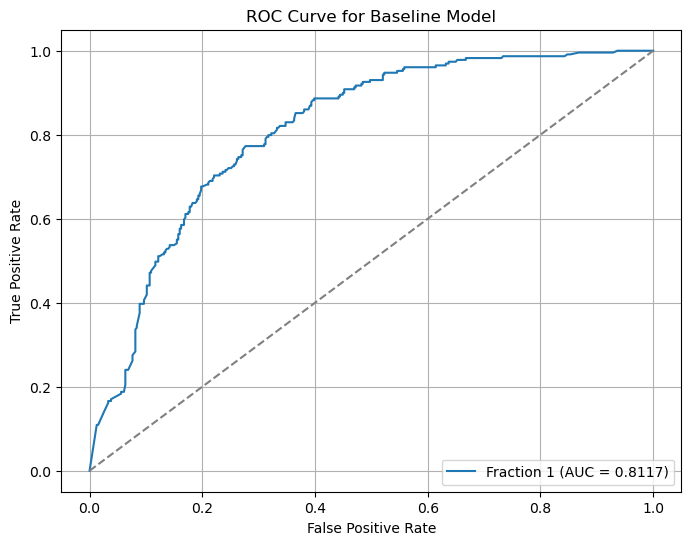

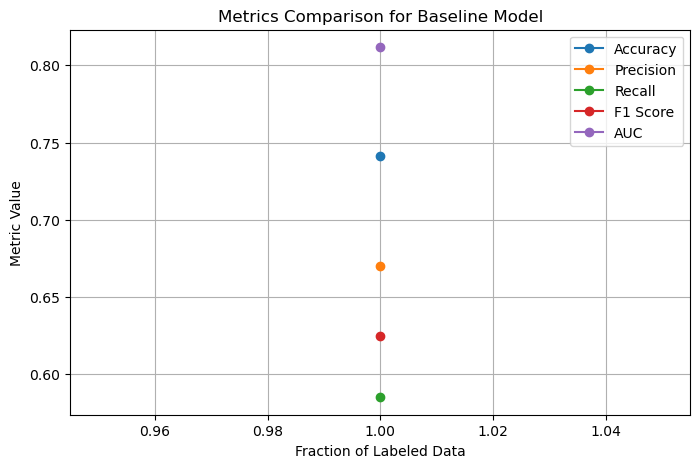

In [17]:
plot_metrics(metrics_data,"baseline_model")

## A.2 Semi supervised learning

### i. Self training classifer

In [18]:
X_train_process

,age,gender,education,country,ethnicity,nscore,escore,oscore,ascore,cscore,impuslive,ss
105,0.49788,-0.48246,-0.05921,0.96082,-0.31685,-2.21844,0.47617,-1.82919,-0.76096,2.04506,-1.37983,-1.54858
73,1.09449,-0.48246,-0.05921,0.96082,-0.31685,-0.67825,-0.57545,-0.31776,0.28783,1.13407,-0.71126,-0.21575
279,1.09449,-0.48246,1.16365,0.96082,-0.31685,-1.32828,0.80523,0.29338,0.43852,0.41594,0.19268,-0.52593
1404,-0.07854,0.48246,1.16365,0.96082,-0.31685,-0.79151,0.80523,1.24033,1.28610,0.41594,0.19268,1.22470
508,0.49788,0.48246,1.16365,-0.28519,-0.31685,-1.05308,1.11406,-0.31776,0.28783,0.12331,-1.37983,-0.52593
...,...,...,...,...,...,...,...,...,...,...,...,...
285,0.49788,-0.48246,0.45468,0.96082,-0.31685,-0.92104,1.28610,-0.71727,-0.30172,0.25953,-1.37983,-0.21575
982,-0.95197,-0.48246,-0.61113,-0.28519,-0.31685,-0.14882,0.32197,1.24033,-0.45321,-0.89891,0.52975,1.22470
857,-0.95197,-0.48246,-0.61113,-0.57009,-0.31685,-1.05308,2.32338,1.06238,-0.15487,0.93949,0.88113,0.76540
1689,-0.07854,0.48246,0.45468,0.96082,-0.31685,0.73545,-0.30033,-0.31776,0.43852,-0.40581,-1.37983,-0.21575


#### Function for Self-training

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.semi_supervised import SelfTrainingClassifier

def self_training(X_train_process, Y_train_process,basemodel,fraction):
    scaler = StandardScaler()
    X_train_process = scaler.fit_transform(X_train_process)
    
    self_training_model = SelfTrainingClassifier(
        base_estimator= basemodel ,
        criterion="k_best",  # Use k_best or threshold for confidence
        k_best=10,           # Number of most confident samples to add in each iteration
        max_iter=10
    )
    
    # Fit the self-training model
    self_training_model.fit(X_train_process, Y_train_process)
    
    # Save the model
    model_filename = f'model/self_training_model_{int(fraction*100)}%.pkl'
    joblib.dump(self_training_model, model_filename)
    print(f"Saved self-training model with {int(fraction*100)}% labeled data to {model_filename}")
    
    return  self_training_model
    

#### Train and evaluate

In [20]:
for fraction in fractions:
    X_train_process, Y_train_process = label_subset[fraction]
    self_training_model = self_training(X_train_process, Y_train_process,gb_model, fraction)
    
    y_pred_st = self_training_model.predict(X_test)
    y_proba_st = self_training_model.predict_proba(X_test)[:, 1]
    metrics_data = evaluation( y_pred_st,y_proba_st, metrics_data,'self_training_model',fraction)

Saved self-training model with 10% labeled data to model/self_training_model_10%.pkl

Model: self_training_model (Fraction: 0.1)
Accuracy: 0.7400
Precision: 0.6502
Recall: 0.6332
F1-Score: 0.6416
AUC: 0.7685

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.80      0.80       394
           1       0.65      0.63      0.64       229

    accuracy                           0.74       623
   macro avg       0.72      0.72      0.72       623
weighted avg       0.74      0.74      0.74       623



/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but SelfTrainingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but SelfTrainingClassifier was fitted without feature names
  warnings.warn(


Saved self-training model with 20% labeled data to model/self_training_model_20%.pkl

Model: self_training_model (Fraction: 0.2)
Accuracy: 0.7287
Precision: 0.6705
Recall: 0.5153
F1-Score: 0.5827
AUC: 0.7882

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.85      0.80       394
           1       0.67      0.52      0.58       229

    accuracy                           0.73       623
   macro avg       0.71      0.68      0.69       623
weighted avg       0.72      0.73      0.72       623



/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but SelfTrainingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but SelfTrainingClassifier was fitted without feature names
  warnings.warn(


Saved self-training model with 30% labeled data to model/self_training_model_30%.pkl

Model: self_training_model (Fraction: 0.3)
Accuracy: 0.7352
Precision: 0.6739
Recall: 0.5415
F1-Score: 0.6005
AUC: 0.8061

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.85      0.80       394
           1       0.67      0.54      0.60       229

    accuracy                           0.74       623
   macro avg       0.72      0.69      0.70       623
weighted avg       0.73      0.74      0.73       623



/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but SelfTrainingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but SelfTrainingClassifier was fitted without feature names
  warnings.warn(


Saved self-training model with 40% labeled data to model/self_training_model_40%.pkl

Model: self_training_model (Fraction: 0.4)
Accuracy: 0.7416
Precision: 0.6910
Recall: 0.5371
F1-Score: 0.6044
AUC: 0.8012

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.86      0.81       394
           1       0.69      0.54      0.60       229

    accuracy                           0.74       623
   macro avg       0.73      0.70      0.71       623
weighted avg       0.74      0.74      0.73       623



/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but SelfTrainingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but SelfTrainingClassifier was fitted without feature names
  warnings.warn(


Saved self-training model with 50% labeled data to model/self_training_model_50%.pkl

Model: self_training_model (Fraction: 0.5)
Accuracy: 0.7400
Precision: 0.6701
Recall: 0.5764
F1-Score: 0.6197
AUC: 0.8157

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.84      0.80       394
           1       0.67      0.58      0.62       229

    accuracy                           0.74       623
   macro avg       0.72      0.71      0.71       623
weighted avg       0.73      0.74      0.74       623



/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but SelfTrainingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but SelfTrainingClassifier was fitted without feature names
  warnings.warn(


In [21]:
print(metrics_data)

{'baseline_model': {1: {'accuracy': 0.7415730337078652, 'precision': 0.67, 'recall': 0.5851528384279476, 'f1_score': 0.6247086247086248, 'roc': (array([0.        , 0.01269036, 0.01522843, 0.02538071, 0.03299492,
       0.03299492, 0.03807107, 0.03807107, 0.05583756, 0.05583756,
       0.06091371, 0.06345178, 0.06345178, 0.06345178, 0.06852792,
       0.07614213, 0.07614213, 0.08121827, 0.08121827, 0.08121827,
       0.08375635, 0.08375635, 0.08883249, 0.08883249, 0.08883249,
       0.09137056, 0.0964467 , 0.0964467 , 0.10152284, 0.10152284,
       0.10152284, 0.10659898, 0.10659898, 0.10659898, 0.10659898,
       0.10913706, 0.10913706, 0.11675127, 0.11675127, 0.12182741,
       0.12182741, 0.12436548, 0.12944162, 0.1319797 , 0.1319797 ,
       0.13451777, 0.13451777, 0.13705584, 0.13959391, 0.14213198,
       0.14213198, 0.14974619, 0.15482234, 0.15482234, 0.15736041,
       0.15736041, 0.15989848, 0.15989848, 0.15989848, 0.16243655,
       0.16243655, 0.16751269, 0.16751269, 0.170050

#### Plot figures for self training model

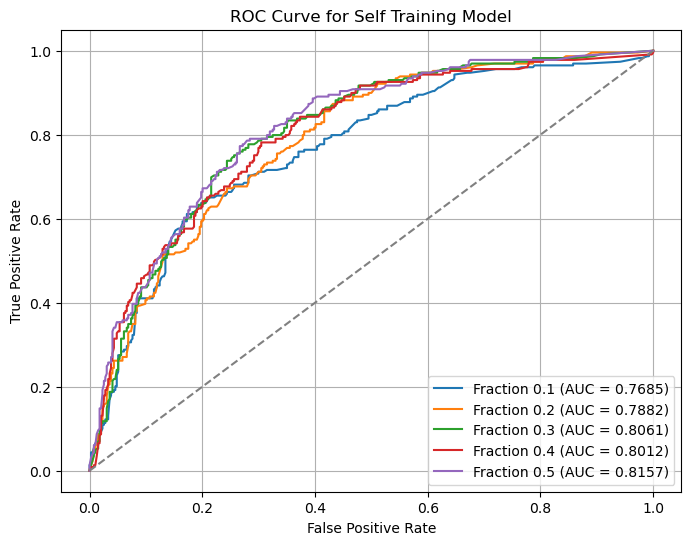

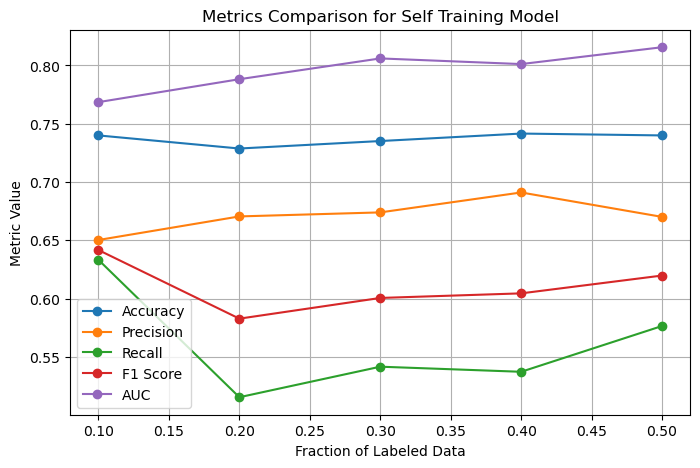

In [22]:
plot_metrics(metrics_data,"self_training_model")

### ii. Co-training classifer

In [23]:
X_train_process

,age,gender,education,country,ethnicity,nscore,escore,oscore,ascore,cscore,impuslive,ss
105,0.49788,-0.48246,-0.05921,0.96082,-0.31685,-2.21844,0.47617,-1.82919,-0.76096,2.04506,-1.37983,-1.54858
73,1.09449,-0.48246,-0.05921,0.96082,-0.31685,-0.67825,-0.57545,-0.31776,0.28783,1.13407,-0.71126,-0.21575
279,1.09449,-0.48246,1.16365,0.96082,-0.31685,-1.32828,0.80523,0.29338,0.43852,0.41594,0.19268,-0.52593
1404,-0.07854,0.48246,1.16365,0.96082,-0.31685,-0.79151,0.80523,1.24033,1.28610,0.41594,0.19268,1.22470
508,0.49788,0.48246,1.16365,-0.28519,-0.31685,-1.05308,1.11406,-0.31776,0.28783,0.12331,-1.37983,-0.52593
...,...,...,...,...,...,...,...,...,...,...,...,...
285,0.49788,-0.48246,0.45468,0.96082,-0.31685,-0.92104,1.28610,-0.71727,-0.30172,0.25953,-1.37983,-0.21575
982,-0.95197,-0.48246,-0.61113,-0.28519,-0.31685,-0.14882,0.32197,1.24033,-0.45321,-0.89891,0.52975,1.22470
857,-0.95197,-0.48246,-0.61113,-0.57009,-0.31685,-1.05308,2.32338,1.06238,-0.15487,0.93949,0.88113,0.76540
1689,-0.07854,0.48246,0.45468,0.96082,-0.31685,0.73545,-0.30033,-0.31776,0.43852,-0.40581,-1.37983,-0.21575


#### Function to split views for classifiers

In [24]:

def random_split(X):
    
    all_features = X.columns.tolist()
    np.random.shuffle(all_features)
    split_index = int(len(all_features) * 0.6)
    view1_features = all_features[:split_index]
    view2_features = all_features[split_index:]
    
    return  view1_features, view2_features


In [25]:
view1_features, view2_features = random_split(X_train)
print("View 1 feature:", view1_features)
print("View 2 feature:", view2_features)


View 1 feature: ['impuslive', 'education', 'ascore', 'age', 'country', 'oscore', 'cscore']
View 2 feature: ['ss', 'nscore', 'ethnicity', 'escore', 'gender']


In [26]:
X_view1 = X_train_process[view1_features]
print(X_view1)

      impuslive  education   ascore      age  country   oscore   cscore
105    -1.37983   -0.05921 -0.76096  0.49788  0.96082 -1.82919  2.04506
73     -0.71126   -0.05921  0.28783  1.09449  0.96082 -0.31776  1.13407
279     0.19268    1.16365  0.43852  1.09449  0.96082  0.29338  0.41594
1404    0.19268    1.16365  1.28610 -0.07854  0.96082  1.24033  0.41594
508    -1.37983    1.16365  0.28783  0.49788 -0.28519 -0.31776  0.12331
...         ...        ...      ...      ...      ...      ...      ...
285    -1.37983    0.45468 -0.30172  0.49788  0.96082 -0.71727  0.25953
982     0.52975   -0.61113 -0.45321 -0.95197 -0.28519  1.24033 -0.89891
857     0.88113   -0.61113 -0.15487 -0.95197 -0.57009  1.06238  0.93949
1689   -1.37983    0.45468  0.43852 -0.07854  0.96082 -0.31776 -0.40581
542    -0.21712    0.45468 -0.76096 -0.07854  0.96082 -0.97631  0.25953

[1262 rows x 7 columns]


#### Function for Co-training

In [27]:
from sklearn.ensemble import RandomForestClassifier
import numpy as np
from sklearn.preprocessing import StandardScaler
import pandas as pd

def co_training(X_train_process, Y_train_process, basemodel, view1_features, view2_features, fraction,max_iterations):
    """
    Perform co-training with two classifiers on two distinct views of the data.
    
    Parameters:
    - X_train_process: Training feature dataset.
    - Y_train_process: Training labels (use -1 for unlabeled samples).
    - gb_model: A pre-defined classifier (e.g., Gradient Boosting).
    - view1_features: Features for the first view.
    - view2_features: Features for the second view.
    - max_iterations: Maximum number of co-training iterations.
    
    Returns:
    - clf_ct1: Trained classifier for view1.
    - clf_ct2: Trained classifier for view2.
    """
    
    # Standardize the feature data
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_process)
    X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train_process.columns)
    
    # Separate the data into two consistent views
    X_view1 = X_train_scaled[view1_features].values
    X_view2 = X_train_scaled[view2_features].values
    
    # Identify labeled and unlabeled indices
    labeled_mask = Y_train_process != -1
    unlabeled_mask = Y_train_process == -1
    
    X_labeled_view1 = X_view1[labeled_mask]
    X_labeled_view2 = X_view2[labeled_mask]
    Y_labeled = Y_train_process[labeled_mask].values
    
    X_unlabeled_view1 = X_view1[unlabeled_mask]
    X_unlabeled_view2 = X_view2[unlabeled_mask]
    
    # Initialize two classifiers
    clf_ct1 = RandomForestClassifier(random_state=42)
    clf_ct2 = basemodel
    
    # Iteratively perform co-training
    for iteration in range(max_iterations):
        print(f"Iteration {iteration + 1}/{max_iterations}")
        
        # Train classifiers on their respective views
        clf_ct1.fit(X_labeled_view1, Y_labeled)
        clf_ct2.fit(X_labeled_view2, Y_labeled)
        
        # Predict probabilities on unlabeled data
        prob1 = clf_ct1.predict_proba(X_unlabeled_view1)
        prob2 = clf_ct2.predict_proba(X_unlabeled_view2)
        
        # Select most confident predictions
        confident_indices_1 = np.where(np.max(prob1, axis=1) > 0.9)[0]
        confident_indices_2 = np.where(np.max(prob2, axis=1) > 0.9)[0]
        
        # Merge confident indices from both classifiers, removing duplicates
        all_confident_indices = np.unique(np.concatenate([confident_indices_1, confident_indices_2]))
        
        # Add confident predictions to labeled data
        new_X_labeled_view1 = []
        new_X_labeled_view2 = []
        new_Y_labeled = []
        
        for idx in all_confident_indices:
            if idx in confident_indices_1:
                new_X_labeled_view1.append(X_unlabeled_view1[idx])
                new_X_labeled_view2.append(X_unlabeled_view2[idx])
                new_Y_labeled.append(clf_ct1.predict(X_unlabeled_view1[idx].reshape(1, -1))[0])
            elif idx in confident_indices_2:
                new_X_labeled_view1.append(X_unlabeled_view1[idx])
                new_X_labeled_view2.append(X_unlabeled_view2[idx])
                new_Y_labeled.append(clf_ct2.predict(X_unlabeled_view2[idx].reshape(1, -1))[0])
        
        # Append new labeled data
        if new_X_labeled_view1:
            X_labeled_view1 = np.vstack((X_labeled_view1, new_X_labeled_view1))
            X_labeled_view2 = np.vstack((X_labeled_view2, new_X_labeled_view2))
            Y_labeled = np.append(Y_labeled, new_Y_labeled)
        
        # Remove confident samples from unlabeled datasets
        X_unlabeled_view1 = np.delete(X_unlabeled_view1, all_confident_indices, axis=0)
        X_unlabeled_view2 = np.delete(X_unlabeled_view2, all_confident_indices, axis=0)
        
        # Stop if there are no confident samples left
        if len(all_confident_indices) == 0:
            print("No confident samples left. Stopping early.")
            break
        
    # Save the model
    model_filename_1 = f'model/co_training_model_1_{int(fraction*100)}%.pkl'
    joblib.dump(clf_ct1, model_filename_1)
    print(f"Saved co-training model 1 with {int(fraction*100)}% labeled data to {model_filename_1}")
    
    model_filename_2 = f'model/co_training_model_2_{int(fraction*100)}%.pkl'
    joblib.dump(clf_ct2, model_filename_2)
    print(f"Saved co-training model 2 with {int(fraction*100)}% labeled data to {model_filename_2}")
    
    return clf_ct1, clf_ct2


In [28]:
type(X_train_process)

pandas.core.frame.DataFrame

#### Train and evaluate

In [29]:
for fraction in fractions:
    # Extract the labeled subset for training
    X_train_process, Y_train_process = label_subset[fraction]
    
    # Train co-training classifiers
    clf_ct1, clf_ct2 = co_training( X_train_process, Y_train_process, gb_model, 
                                    view1_features, view2_features,fraction, max_iterations=5)
    
    # Create feature subsets for testing
    X_test_view1 = X_test[view1_features]
    X_test_view2 = X_test[view2_features]

    # Predictions from each classifier
    y_pred_ct1 = clf_ct1.predict(X_test_view1)
    y_pred_ct2 = clf_ct2.predict(X_test_view2)

    # Majority Voting: Use predictions where classifiers agree, random choice otherwise
    y_pred_final = np.where(
        y_pred_ct1 == y_pred_ct2, 
        y_pred_ct1, 
        np.random.choice([0, 1], size=y_pred_ct1.shape)
    )
    
    # Predicted probabilities for ROC and AUC
    y_prob_ct1 = clf_ct1.predict_proba(X_test_view1)[:, 1]
    y_prob_ct2 = clf_ct2.predict_proba(X_test_view2)[:, 1]

    # Average probabilities for final probabilistic decision
    y_proba_final = (y_prob_ct1 + y_prob_ct2) / 2
    
    # Evaluate individual classifiers and final model
    metrics_data = evaluation(y_pred_ct1, y_prob_ct1, metrics_data, 'co_training_model1', fraction)
    metrics_data = evaluation(y_pred_ct2, y_prob_ct2, metrics_data, 'co_training_model2', fraction)
    metrics_data = evaluation(y_pred_final, y_proba_final, metrics_data, 'co_training_model', fraction)

Iteration 1/5
Iteration 2/5
Iteration 3/5
Iteration 4/5
Iteration 5/5
Saved co-training model 1 with 10% labeled data to model/co_training_model_1_10%.pkl
Saved co-training model 2 with 10% labeled data to model/co_training_model_2_10%.pkl

Model: co_training_model1 (Fraction: 0.1)
Accuracy: 0.7159
Precision: 0.6226
Recall: 0.5764
F1-Score: 0.5986
AUC: 0.7773

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.80      0.78       394
           1       0.62      0.58      0.60       229

    accuracy                           0.72       623
   macro avg       0.69      0.69      0.69       623
weighted avg       0.71      0.72      0.71       623


Model: co_training_model2 (Fraction: 0.1)
Accuracy: 0.6629
Precision: 0.5463
Recall: 0.4891
F1-Score: 0.5161
AUC: 0.7258

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.76      0.74       394
           1       0.55      0.4

/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(


Iteration 2/5
Iteration 3/5
Iteration 4/5
Iteration 5/5
Saved co-training model 1 with 20% labeled data to model/co_training_model_1_20%.pkl
Saved co-training model 2 with 20% labeled data to model/co_training_model_2_20%.pkl

Model: co_training_model1 (Fraction: 0.2)
Accuracy: 0.7287
Precision: 0.6389
Recall: 0.6026
F1-Score: 0.6202
AUC: 0.7797

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.80      0.79       394
           1       0.64      0.60      0.62       229

    accuracy                           0.73       623
   macro avg       0.71      0.70      0.70       623
weighted avg       0.73      0.73      0.73       623



/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(



Model: co_training_model2 (Fraction: 0.2)
Accuracy: 0.6661
Precision: 0.5705
Recall: 0.3712
F1-Score: 0.4497
AUC: 0.7342

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.84      0.76       394
           1       0.57      0.37      0.45       229

    accuracy                           0.67       623
   macro avg       0.63      0.60      0.61       623
weighted avg       0.65      0.67      0.65       623


Model: co_training_model (Fraction: 0.2)
Accuracy: 0.7063
Precision: 0.6237
Recall: 0.5066
F1-Score: 0.5590
AUC: 0.7987

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.82      0.78       394
           1       0.62      0.51      0.56       229

    accuracy                           0.71       623
   macro avg       0.68      0.66      0.67       623
weighted avg       0.70      0.71      0.70       623

Iteration 1/5
Iteration 2/5
Iteration 3/5
Iteration 4/5

/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(


Iteration 2/5
Iteration 3/5
Iteration 4/5
Iteration 5/5
Saved co-training model 1 with 40% labeled data to model/co_training_model_1_40%.pkl
Saved co-training model 2 with 40% labeled data to model/co_training_model_2_40%.pkl

Model: co_training_model1 (Fraction: 0.4)
Accuracy: 0.7175
Precision: 0.6293
Recall: 0.5633
F1-Score: 0.5945
AUC: 0.7752

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.81      0.78       394
           1       0.63      0.56      0.59       229

    accuracy                           0.72       623
   macro avg       0.70      0.69      0.69       623
weighted avg       0.71      0.72      0.71       623


Model: co_training_model2 (Fraction: 0.4)
Accuracy: 0.6693
Precision: 0.5983
Recall: 0.3057
F1-Score: 0.4046
AUC: 0.7401

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.88      0.77       394
           1       0.60      0.31      0.40   

/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(



Model: co_training_model (Fraction: 0.4)
Accuracy: 0.6886
Precision: 0.6115
Recall: 0.4192
F1-Score: 0.4974
AUC: 0.7944

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.85      0.77       394
           1       0.61      0.42      0.50       229

    accuracy                           0.69       623
   macro avg       0.66      0.63      0.64       623
weighted avg       0.68      0.69      0.67       623

Iteration 1/5
Iteration 2/5
Iteration 3/5
Iteration 4/5
Iteration 5/5
Saved co-training model 1 with 50% labeled data to model/co_training_model_1_50%.pkl
Saved co-training model 2 with 50% labeled data to model/co_training_model_2_50%.pkl

Model: co_training_model1 (Fraction: 0.5)
Accuracy: 0.7255
Precision: 0.6330
Recall: 0.6026
F1-Score: 0.6174
AUC: 0.7804

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.80      0.79       394
           1       0.63      0.60

/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(


#### Plot figures for co training model 1 and 2

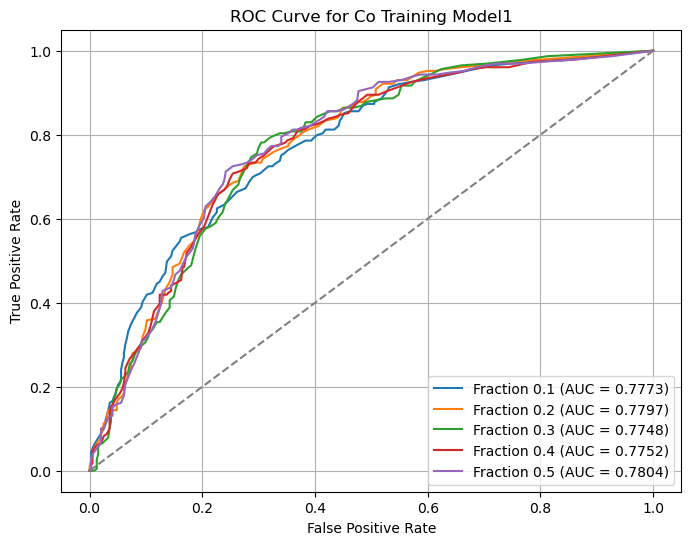

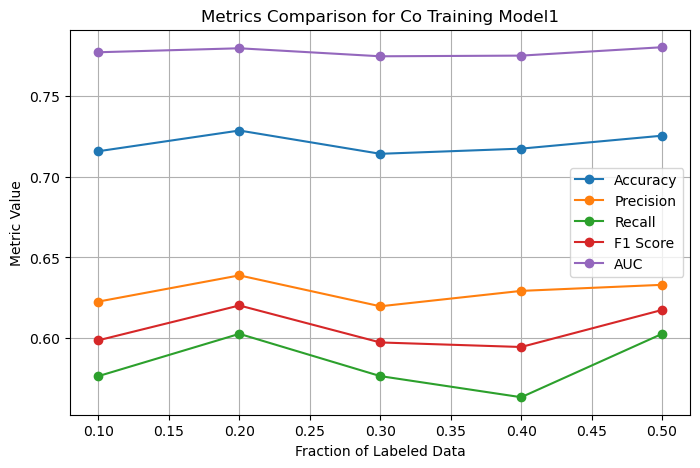

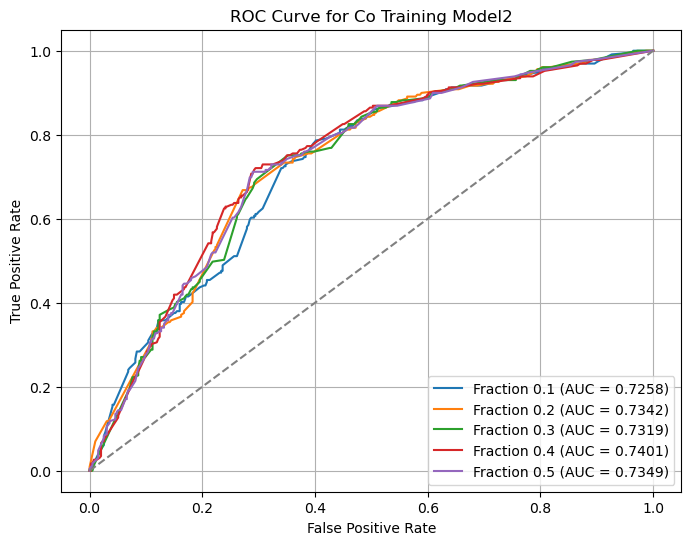

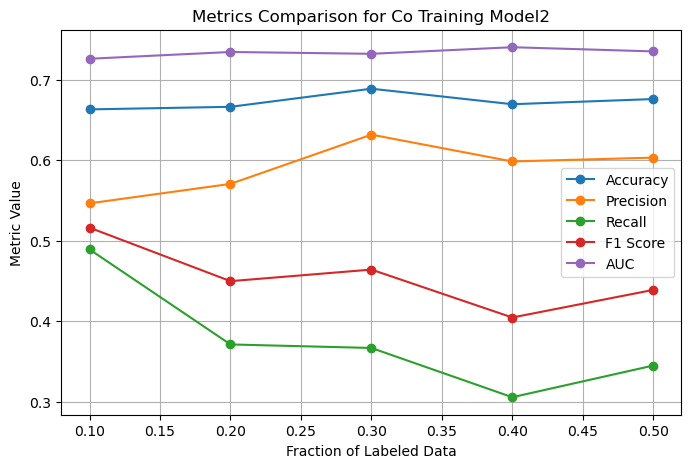

In [30]:
plot_metrics(metrics_data,"co_training_model1")
plot_metrics(metrics_data,"co_training_model2")

#### Plot figures for co training model

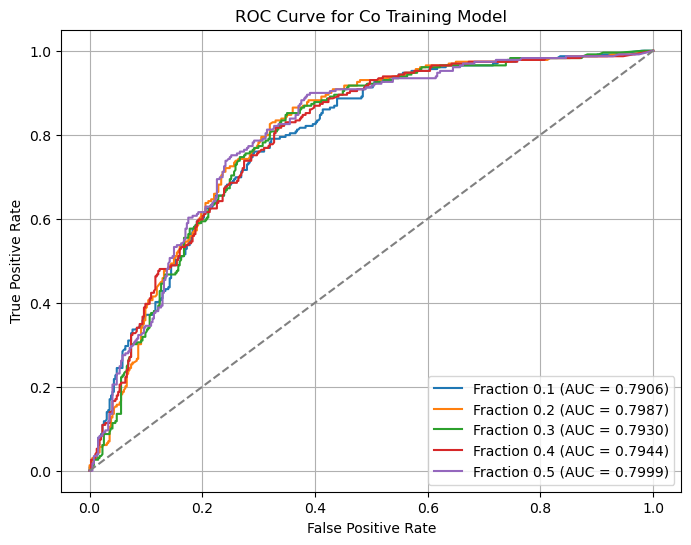

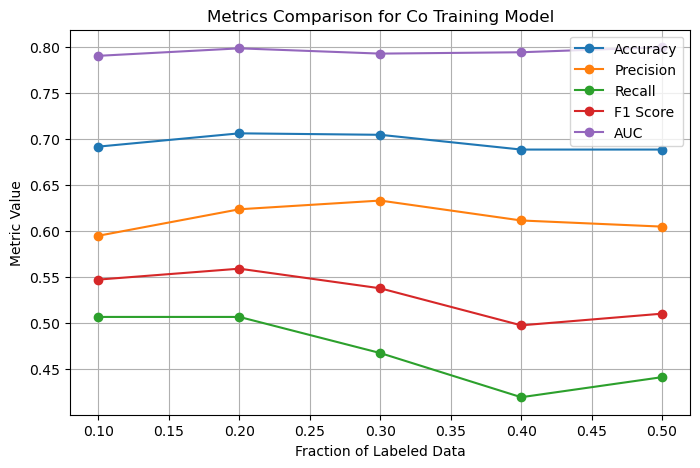

In [31]:
plot_metrics(metrics_data,"co_training_model")

### iii. Semi-supervised ensemble

#### Function for Semiboosting

In [32]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from LAMDA_SSL.Algorithm.Classification.SemiBoost import SemiBoost

def semiboosting(X_train_process, Y_train_process, basemodel,fraction):

    # Separate labeled and unlabeled data
    labeled_indices = Y_train_process[Y_train_process != -1].index
    unlabeled_indices = Y_train_process[Y_train_process == -1].index

    X_labeled = X_train_process.loc[labeled_indices].to_numpy()
    Y_labeled = Y_train_process.loc[labeled_indices].to_numpy()
    X_unlabeled = X_train_process.loc[unlabeled_indices].to_numpy()

    # Initialize SemiBoost with base model
    sb_model = SemiBoost(
        base_estimator = basemodel ,  
        T= 100,  # Number of boosting iterations
        sample_percent=0.3,  # Percent of unlabeled data sampled per iteration
        #similarity_kernel='rbf',  # Kernel type for similarity computation
        gamma = 0.8
    )

    # Fit the SemiBoost model
    sb_model.fit(X_labeled, Y_labeled, X_unlabeled)
    
    # Save the model
    model_filename = f'model/semiboosting_model_{int(fraction*100)}%.pkl'
    joblib.dump(sb_model, model_filename)
    print(f"Saved SemiBoost model with {int(fraction*100)}% labeled data to {model_filename}")

    return  sb_model


Modify predict Predict probabilities for SemiBoost with a fixed np.float issue.

In [33]:
def patched_predict_proba(self, X):
    # Use float instead of np.float to avoid the AttributeError
    y_proba = np.full((X.shape[0], 2), 0, float)
    for i in range(len(self.models)):
        y_proba = np.add(y_proba, self.weights[i] * self.models[i].predict_proba(X))
    return y_proba
# Apply the patch to the SemiBoost class
SemiBoost.predict_proba = patched_predict_proba

#### Train and evaluate

In [34]:
for fraction in fractions:
    
    X_train_process, Y_train_process = label_subset[fraction]
    semiboosting_model = semiboosting(X_train_process, Y_train_process, gb_model,fraction)
    
    # Evaluate the model
    y_pred_sb = semiboosting_model.predict(X_test)
    y_proba_sb = semiboosting_model.predict_proba(X_test)[:, 1]  # Probability for the positive class
    metrics_data = evaluation(y_pred_sb, y_proba_sb, metrics_data, "semi_boosting_model", fraction)

Saved SemiBoost model with 10% labeled data to model/semiboosting_model_10%.pkl

Model: semi_boosting_model (Fraction: 0.1)
Accuracy: 0.7287
Precision: 0.6327
Recall: 0.6245
F1-Score: 0.6286
AUC: 0.7957

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.79      0.79       394
           1       0.63      0.62      0.63       229

    accuracy                           0.73       623
   macro avg       0.71      0.71      0.71       623
weighted avg       0.73      0.73      0.73       623



/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, b

Saved SemiBoost model with 20% labeled data to model/semiboosting_model_20%.pkl

Model: semi_boosting_model (Fraction: 0.2)
Accuracy: 0.7255
Precision: 0.6295
Recall: 0.6157
F1-Score: 0.6225
AUC: 0.7984

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.79      0.78       394
           1       0.63      0.62      0.62       229

    accuracy                           0.73       623
   macro avg       0.70      0.70      0.70       623
weighted avg       0.72      0.73      0.72       623



/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, b

Saved SemiBoost model with 30% labeled data to model/semiboosting_model_30%.pkl

Model: semi_boosting_model (Fraction: 0.3)
Accuracy: 0.7400
Precision: 0.6476
Recall: 0.6419
F1-Score: 0.6447
AUC: 0.8050

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.80      0.79       394
           1       0.65      0.64      0.64       229

    accuracy                           0.74       623
   macro avg       0.72      0.72      0.72       623
weighted avg       0.74      0.74      0.74       623



/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, b

Saved SemiBoost model with 40% labeled data to model/semiboosting_model_40%.pkl

Model: semi_boosting_model (Fraction: 0.4)
Accuracy: 0.7544
Precision: 0.6638
Recall: 0.6725
F1-Score: 0.6681
AUC: 0.8132

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.80      0.81       394
           1       0.66      0.67      0.67       229

    accuracy                           0.75       623
   macro avg       0.74      0.74      0.74       623
weighted avg       0.76      0.75      0.75       623



/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, b

Saved SemiBoost model with 50% labeled data to model/semiboosting_model_50%.pkl

Model: semi_boosting_model (Fraction: 0.5)
Accuracy: 0.7368
Precision: 0.6471
Recall: 0.6245
F1-Score: 0.6356
AUC: 0.8034

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.80      0.79       394
           1       0.65      0.62      0.64       229

    accuracy                           0.74       623
   macro avg       0.72      0.71      0.71       623
weighted avg       0.73      0.74      0.74       623



/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, b

#### Plot figures for semi boosting model

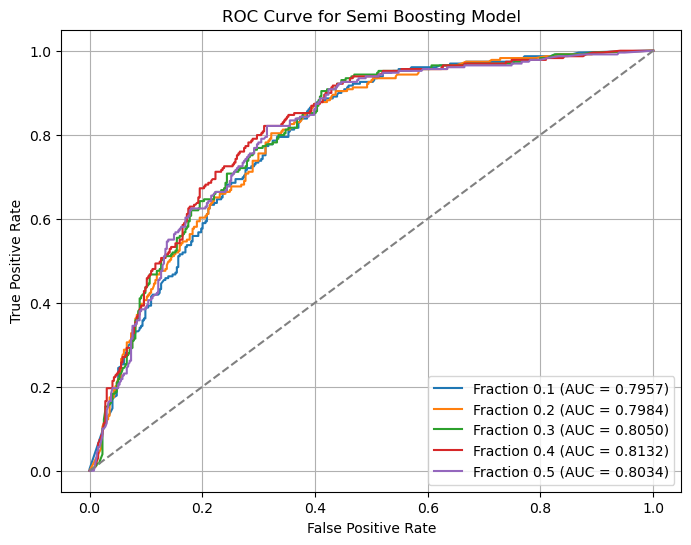

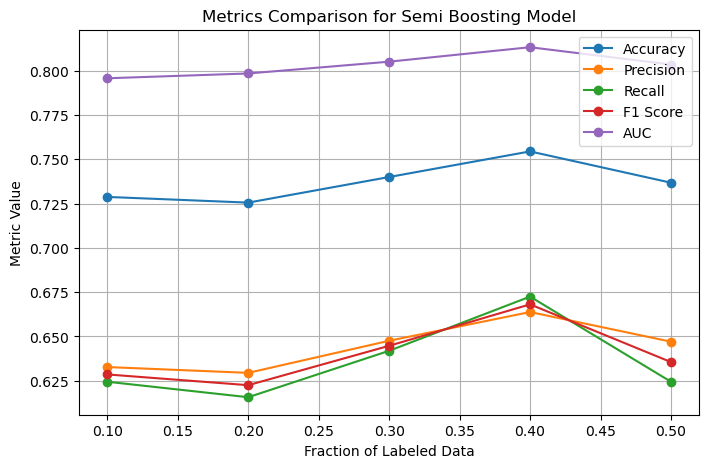

In [35]:
plot_metrics(metrics_data,"semi_boosting_model")

### iv. Intrinsically semi-supervised learning method

#### Function for label spreading

In [36]:
from sklearn.semi_supervised import LabelSpreading

def labelspreading(X_train_process, Y_train_process,fraction):
    
    # Scale the features
    scaler = StandardScaler()
    X_train_process = scaler.fit_transform(X_train_process)
    
    
    label_spreading_model = LabelSpreading(kernel="rbf", gamma=0.3, max_iter=30)  # Use RBF kernel for similarity
    label_spreading_model.fit(X_train_process, Y_train_process)
    
    # Save the model
    model_filename = f'model/label_spreading_model_{int(fraction*100)}%.pkl'
    joblib.dump(label_spreading_model, model_filename)
    print(f"Saved label_spreading_model with {int(fraction*100)}% labeled data to {model_filename}")
    
 
    return label_spreading_model

#### Train and evaluate

In [37]:
for fraction in fractions:
    
    X_train_process, Y_train_process = label_subset[fraction]
    labelspreading_model = labelspreading(X_train_process, Y_train_process,fraction)
    
    # Evaluate the model
    y_pred_ls = labelspreading_model.predict(X_test)
    y_proba_ls = labelspreading_model.predict_proba(X_test)[:, 1]  # Probability for the positive class
    metrics_data = evaluation(y_pred_ls, y_proba_ls, metrics_data, "label_spreading_model", fraction)

Saved label_spreading_model with 10% labeled data to model/label_spreading_model_10%.pkl

Model: label_spreading_model (Fraction: 0.1)
Accuracy: 0.7480
Precision: 0.6782
Recall: 0.5983
F1-Score: 0.6357
AUC: 0.8158

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.84      0.81       394
           1       0.68      0.60      0.64       229

    accuracy                           0.75       623
   macro avg       0.73      0.72      0.72       623
weighted avg       0.74      0.75      0.74       623

Saved label_spreading_model with 20% labeled data to model/label_spreading_model_20%.pkl

Model: label_spreading_model (Fraction: 0.2)
Accuracy: 0.7464
Precision: 0.7126
Recall: 0.5197
F1-Score: 0.6010
AUC: 0.8165

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.88      0.81       394
           1       0.71      0.52      0.60       229

    accuracy                     

/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but LabelSpreading was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but LabelSpreading was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but LabelSpreading was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but LabelSpreading was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but LabelSpreading was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but LabelSpreading was fitted without feature names
  warning

Saved label_spreading_model with 50% labeled data to model/label_spreading_model_50%.pkl

Model: label_spreading_model (Fraction: 0.5)
Accuracy: 0.7319
Precision: 0.6782
Recall: 0.5153
F1-Score: 0.5856
AUC: 0.8142

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.86      0.80       394
           1       0.68      0.52      0.59       229

    accuracy                           0.73       623
   macro avg       0.72      0.69      0.69       623
weighted avg       0.73      0.73      0.72       623



/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but LabelSpreading was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but LabelSpreading was fitted without feature names
  warnings.warn(


#### Plot figures for label spreading model

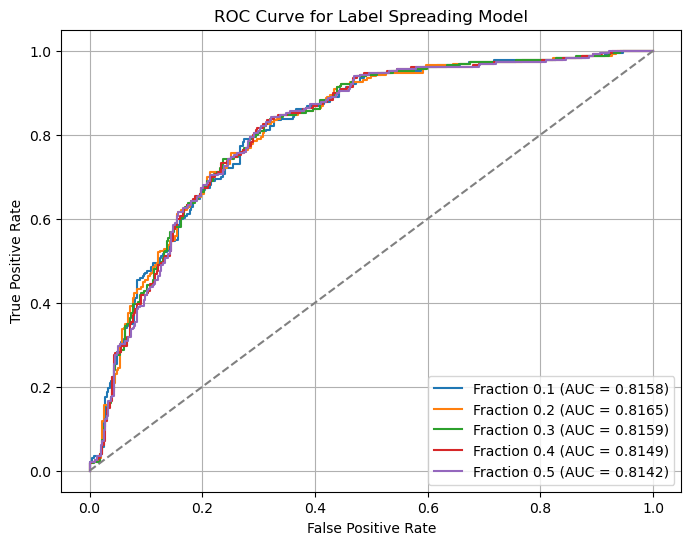

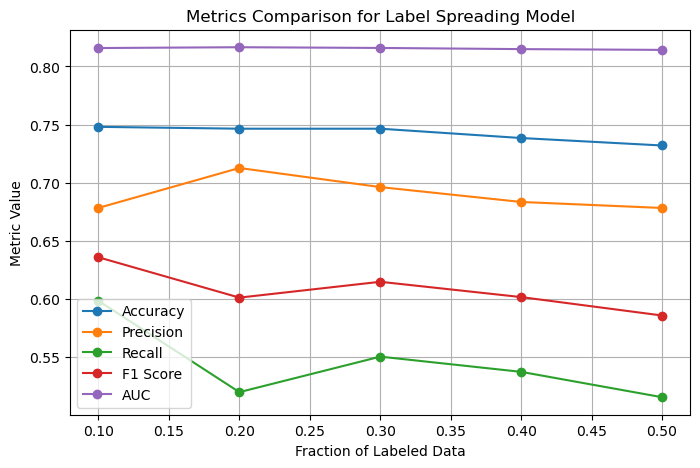

In [38]:
plot_metrics(metrics_data,"label_spreading_model")

## B. Overall evaluate

In [39]:
metrics_data

{'baseline_model': {1: {'accuracy': 0.7415730337078652,
   'precision': 0.67,
   'recall': 0.5851528384279476,
   'f1_score': 0.6247086247086248,
   'roc': (array([0.        , 0.01269036, 0.01522843, 0.02538071, 0.03299492,
           0.03299492, 0.03807107, 0.03807107, 0.05583756, 0.05583756,
           0.06091371, 0.06345178, 0.06345178, 0.06345178, 0.06852792,
           0.07614213, 0.07614213, 0.08121827, 0.08121827, 0.08121827,
           0.08375635, 0.08375635, 0.08883249, 0.08883249, 0.08883249,
           0.09137056, 0.0964467 , 0.0964467 , 0.10152284, 0.10152284,
           0.10152284, 0.10659898, 0.10659898, 0.10659898, 0.10659898,
           0.10913706, 0.10913706, 0.11675127, 0.11675127, 0.12182741,
           0.12182741, 0.12436548, 0.12944162, 0.1319797 , 0.1319797 ,
           0.13451777, 0.13451777, 0.13705584, 0.13959391, 0.14213198,
           0.14213198, 0.14974619, 0.15482234, 0.15482234, 0.15736041,
           0.15736041, 0.15989848, 0.15989848, 0.15989848, 0.16243

#### Line plot for AUC

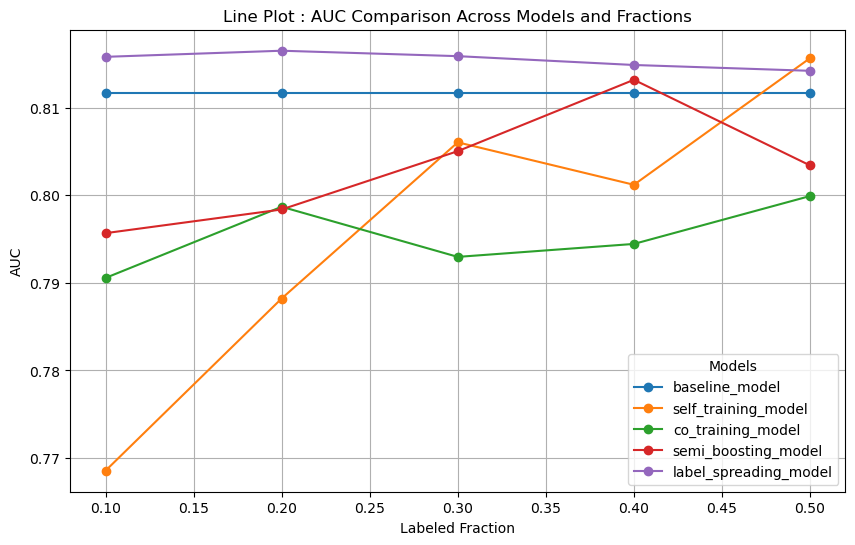

In [40]:
import matplotlib.pyplot as plt
import numpy as np

def compare_auc(metrics_data):

    # Models to exclude
    excluded_models = {'co_training_model1', 'co_training_model2'}

    # Define fractions to plot
    fractions = [0.1, 0.2, 0.3, 0.4, 0.5]

    # Prepare AUC data for each model, excluding specific models
    auc_data = {}
    for model, data in metrics_data.items():
        if model in excluded_models:
            continue  # Skip excluded models
        auc_values = []
        for fraction in fractions:
            # For baseline, assign the AUC at fraction=1 to all other fractions
            if model == "baseline_model":
                auc_values = [data[1]['roc'][2]] * len(fractions)
                break
            auc_values.append(data.get(fraction, {}).get('roc', (None, None, None))[2])
        auc_data[model] = auc_values

    # Plot
    plt.figure(figsize=(10, 6))
    for model, auc_values in auc_data.items():
        plt.plot(fractions, auc_values, label=model, marker='o')

    # Plot customization
    plt.title("Line Plot : AUC Comparison Across Models and Fractions")
    plt.xlabel("Labeled Fraction")
    plt.ylabel("AUC")
    plt.legend(title="Models")
    plt.grid(True)

    plt.show()
       
compare_auc(metrics_data)

#### Heatmap for AUC

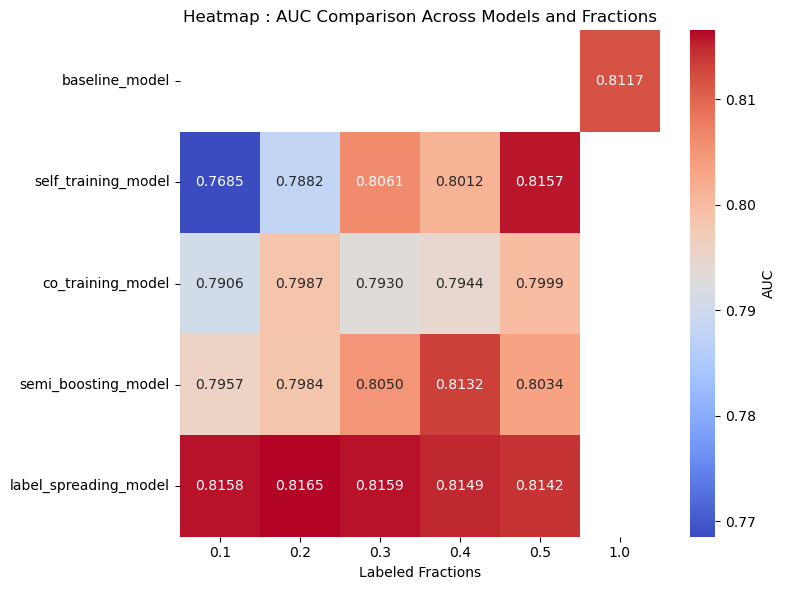

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def compare_auc(metrics_data):
    # Models to exclude
    excluded_models = {'co_training_model1', 'co_training_model2'}

    # Prepare the data
    heatmap_data = {}
    for model, data in metrics_data.items():
        if model in excluded_models:
            continue  # Skip excluded models
        if model == "baseline_model":
            heatmap_data[model] = [None, None, None, None, None, data[1]['roc'][2]]  # Only valid at fraction=1
        else:
            auc_values = [data.get(fraction, {}).get('roc', (None, None, None))[2] for fraction in [0.1, 0.2, 0.3, 0.4, 0.5]]
            heatmap_data[model] = auc_values + [None]  # No valid AUC for fraction=1

    # Convert to DataFrame
    fractions = [0.1, 0.2, 0.3, 0.4, 0.5, 1.0]  # Include fraction=1 for the baseline model
    df_heatmap = pd.DataFrame(heatmap_data, index=fractions).T

    # Generate a mask for missing values
    mask = pd.isna(df_heatmap)

    # Fill NaN with 0 for visualization but keep the mask for the heatmap
    df_heatmap_filled = df_heatmap.fillna(0)

    # Generate the heatmap
    plt.figure(figsize=(8, 6))
    sns.heatmap(df_heatmap_filled, annot=True, fmt=".4f", cmap="coolwarm", cbar_kws={'label': 'AUC'}, mask=mask)
    plt.title("Heatmap : AUC Comparison Across Models and Fractions")
    plt.xlabel("Labeled Fractions")
    #plt.ylabel("Models")
    plt.tight_layout()
    plt.show()


compare_auc(metrics_data)

#### Line plot for F1 Score

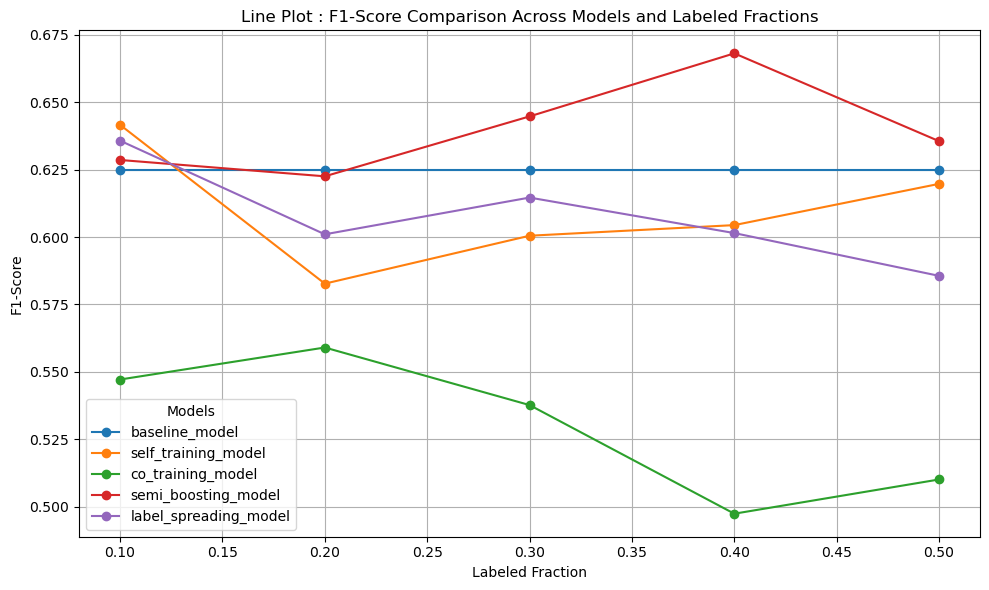

In [42]:
def compare_f1(metrics_data):
    
    # Models to exclude
    excluded_models = {'co_training_model1', 'co_training_model2'}

    # Define fractions
    fractions = [0.1, 0.2, 0.3, 0.4, 0.5]

    # Prepare F1-score data for each model
    f1_data = {}
    for model, data in metrics_data.items():
        if model in excluded_models:
            continue  # Skip excluded models
        f1_scores = []
        for fraction in fractions:
            if model == "baseline_model":
                f1_scores = [data[1]['f1_score']] * len(fractions)  # Baseline is constant
                break
            f1_scores.append(data.get(fraction, {}).get('f1_score', None))  # Fetch F1-score
        f1_data[model] = f1_scores

    # Plot
    plt.figure(figsize=(10, 6))
    for model, f1_scores in f1_data.items():
        plt.plot(fractions, f1_scores, label=model, marker='o')

    # Customizations
    plt.title("Line Plot : F1-Score Comparison Across Models and Labeled Fractions")
    plt.xlabel("Labeled Fraction")
    plt.ylabel("F1-Score")
    plt.legend(title="Models")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    
compare_f1(metrics_data)


### Heatmap for F1 score

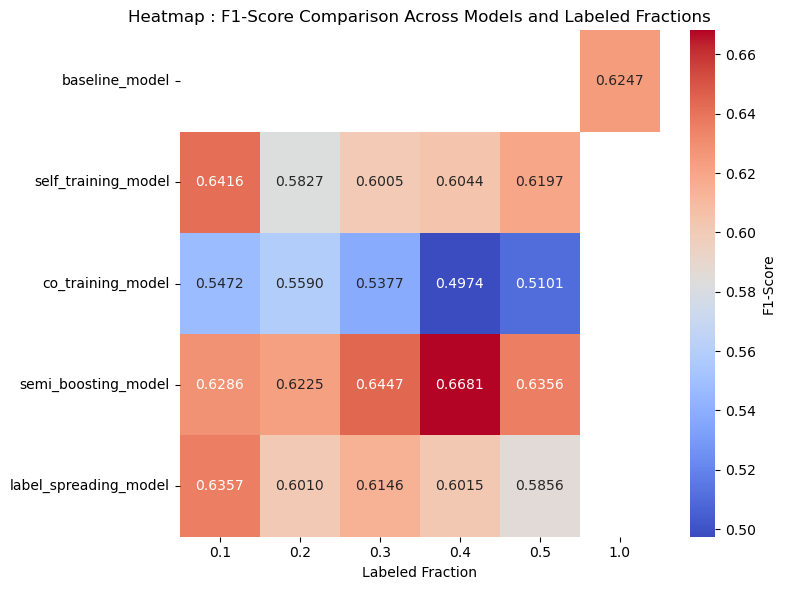

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def compare_f1(metrics_data):
    
    # Models to exclude
    excluded_models = {'co_training_model1', 'co_training_model2'}

    # Define fractions
    fractions = [0.1, 0.2, 0.3, 0.4, 0.5, 1.0]  # Include 1.0 for baseline_model

    # Prepare data for heatmap
    heatmap_data = {}
    for model, data in metrics_data.items():
        if model in excluded_models:
            continue  # Skip excluded models
        f1_scores = []
        for fraction in fractions:
            if model == "baseline_model" and fraction != 1.0:
                f1_scores.append(None)  # No data for baseline_model at other fractions
            else:
                f1_scores.append(data.get(fraction, {}).get('f1_score', None))
        heatmap_data[model] = f1_scores

    # Convert to DataFrame for heatmap
    df_heatmap = pd.DataFrame(heatmap_data, index=fractions).T
    
    # Generate a mask for missing values
    mask = pd.isna(df_heatmap)
    
    # Replace NaN values for plotting purposes (e.g., 0 or other placeholder)
    df_heatmap_filled = df_heatmap.fillna(0)

    # Create the heatmap
    plt.figure(figsize=(8, 6))
    sns.heatmap(df_heatmap_filled, annot=True, fmt=".4f", cmap="coolwarm", cbar_kws={'label': 'F1-Score'}, mask = mask)
    plt.title("Heatmap : F1-Score Comparison Across Models and Labeled Fractions")
    plt.xlabel("Labeled Fraction")
    #plt.ylabel("Models")
    plt.tight_layout()
    plt.show()


compare_f1(metrics_data)